---
title: "Why layers: the single-slab error in v0"
---

# Why layers: the single-slab error in v0

plumax's forward model and its observation operator put the whole methane column in one slab at one pressure and temperature. radtrax's v0 forward model, [`ForwardModel`](xref:api#radtrax.ForwardModel), puts it in layers. This notebook runs both on the same column and reproduces the *radtrax · 3* finding: a slab at the lowest layer's pressure misstates a band's optical depth by up to 19 %, because it broadens every line as if all the methane sat near the surface. A slab at the column's pressure-weighted mean does better, but is still off by 3 %.

**What you'll learn:**

1. How to compose a layered forward model: opacity, solver, surface, geometry, instrument.
2. How large the single-slab error is, band by band.
3. How to get the matched-filter target $t = \partial \ln y / \partial \Delta X$ from the layered model by autodiff.

## Background

Beer–Lambert along the two-way path gives the radiance at the top of the atmosphere, and a band integrates it over the instrument's spectral response $f_b$:

$$L(\nu) = \frac{E_0 \mu_0}{\pi} A \exp\Big(-m \sum_l \tau_l(\nu)\Big), \qquad y_b = \sum_g f_{bg} L(\nu_g)$$

with $m = 1/\mu_0 + 1/\mu$ the air-mass factor and $\tau_l = \sigma(\nu; p_l, T_l)\, n_l x_l \Delta z_l$ layer $l$'s optical depth. A line's width grows with pressure, so the same column of methane absorbs differently at 1 atm and at 0.3 atm; a single slab must pick one. We compare a band's optical depth $\tau_b = -\ln(y_b / y_b^{\text{no gas}})$ through 20 layers and through one slab holding the same column.

The cross sections are *radtrax · 3*'s synthetic spectrum: 150 Voigt lines near 4300 cm⁻¹, built in about a second, so the notebook runs without HITRAN. With HITRAN tables, build them with `python -m radtrax.spectroscopy.hitran CH4` and load them with `radtrax.spectroscopy.load_opacity`.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "radtrax @ git+https://github.com/jejjohnson/radtrax@main",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import jax


jax.config.update("jax_enable_x64", True)

import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from scipy.special import voigt_profile

import radtrax
from radtrax.atmosphere import (
    AVOGADRO_PER_MOL,
    BOLTZMANN_J_PER_K,
    AtmosphericState,
    ViewingGeometry,
)
from radtrax.instrument import BandInstrument
from radtrax.solvers import BeerLambert
from radtrax.spectroscopy import TableOpacity
from radtrax.surface import Lambertian

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p numpy,jax,equinox,radtrax")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.16
IPython version      : 9.10.0

numpy  : 2.4.4
jax    : 0.11.2
equinox: 0.13.8
radtrax: 0.0.0

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.18.44-fc-v114
Machine     : x86_64
Processor   : x86_64
CPU cores   : 2
Architecture: 64bit



## 1. The cross-section table

σ(ν; T, p) on 4230–4370 cm⁻¹ at 0.01 cm⁻¹, ten pressures (0.03–1.1 atm) and six temperatures (200–310 K): line strengths log-normal at 296 K, Lorentz widths $\gamma_{\text{air}} (p / 1\,\text{atm}) (296/T)^{0.75}$, Doppler widths of CH₄. The format is the one `radtrax.spectroscopy.hitran` writes.

In [4]:
NU = np.arange(4230.0, 4370.0, 0.01)  # cm⁻¹                               (G,)
P_ATM = np.geomspace(0.03, 1.1, 10)  # atm                                 (P,)
T_K = np.linspace(200.0, 310.0, 6)  # K                                    (T,)
GAMMA_AIR, N_AIR, C2 = 0.06, 0.75, 1.4387769  # cm⁻¹/atm, -, cm K
CH4_KG = 16.04e-3 / AVOGADRO_PER_MOL  # one CH₄ molecule
C_LIGHT = 2.998e8  # m/s

rng = np.random.default_rng(0)
line_nu = rng.uniform(4252.0, 4348.0, 150)
line_s = rng.lognormal(0.0, 1.2, 150) * 2e-22  # cm/molecule at 296 K
line_e = rng.uniform(0.0, 600.0, 150)  # lower-state energy, cm⁻¹
sigma = np.zeros((NU.size, T_K.size, P_ATM.size))
for j, t in enumerate(T_K):
    # S(T) = S₀ (296/T)^1.5 exp(−c₂ E (1/T − 1/296)); σ_D = ν √(kT/m) / c
    s_t = line_s * (296 / t) ** 1.5 * np.exp(-C2 * line_e * (1 / t - 1 / 296))
    sig_d = line_nu * np.sqrt(BOLTZMANN_J_PER_K * t / CH4_KG) / C_LIGHT
    for i, p in enumerate(P_ATM):
        gamma = GAMMA_AIR * p * (296 / t) ** N_AIR
        for k in range(150):
            lo, hi = np.searchsorted(NU, [line_nu[k] - 5, line_nu[k] + 5])
            profile = voigt_profile(NU[lo:hi] - line_nu[k], sig_d[k], gamma)
            sigma[lo:hi, j, i] += s_t[k] * profile

table = xr.Dataset(
    {
        "absorption_cross_section": (
            ("wavenumber", "temperature", "pressure"),
            sigma,
        )
    },
    coords={"wavenumber": NU, "temperature": T_K, "pressure": P_ATM},
)

## 2. The forward model

[`TableOpacity`](xref:api#radtrax.spectroscopy.TableOpacity) interpolates σ bilinearly in $(\ln p, T)$ for each layer, [`BeerLambert`](xref:api#radtrax.solvers.BeerLambert) gives the radiance, and [`BandInstrument`](xref:api#radtrax.instrument.BandInstrument) integrates seven Gaussian bands, 8.5 nm wide and 14 cm⁻¹ apart, as in *radtrax · 3*.

In [5]:
centres = np.arange(4257.0, 4345.0, 14.0)  # cm⁻¹                          (B,)
# An 8.5 nm FWHM is ν² Δλ / 10⁷ in wavenumber: 15.7 cm⁻¹ at 4300 cm⁻¹.
fwhm_cm = centres**2 * 8.5 / 1e7
sd_cm = fwhm_cm / (2 * np.sqrt(2 * np.log(2)))
response = np.exp(-0.5 * ((NU[None] - centres[:, None]) / sd_cm[:, None]) ** 2)
response /= response.sum(axis=1, keepdims=True)  # each row sums to 1   (B, G)

model = radtrax.ForwardModel(
    TableOpacity.from_datasets({"CH4": table}),
    BeerLambert(),
    BandInstrument(NU, response),
)
geometry = ViewingGeometry.from_angles(35.0, 0.0)
surface = Lambertian(1.0)

## 3. Twenty layers against one slab

Twenty one-kilometre layers with an 8 km scale height and a 6.5 K/km lapse rate down to 217 K, holding 1.9 ppm of methane. The two slabs hold the same column, at the lowest layer's $(p, T)$ (0.94 atm, 285 K) and at the column's air-weighted mean $(p, T)$.

In [6]:
z_km = np.arange(0.5, 20.0, 1.0)  # layer middles                        (L,)
p_atm = np.exp(-z_km / 8.0)
t_k = np.maximum(288.0 - 6.5 * z_km, 217.0)
X0 = 1.9e-6


def state(p_atm, t_k, dz_m, vmr) -> AtmosphericState:
    return AtmosphericState(
        p_pa=jnp.asarray(p_atm * 101325.0),
        t_k=jnp.asarray(t_k),
        z_m=jnp.zeros(np.size(p_atm)),
        dz_m=jnp.asarray(dz_m),
        vmr={"CH4": jnp.asarray(vmr)},
    )


layered = state(p_atm, t_k, np.full(20, 1000.0), np.full(20, X0))
column = float(layered.column("CH4"))  # molecules/cm²
weights = np.asarray(layered.air_column())
weights = weights / weights.sum()


def slab_at(p, t) -> AtmosphericState:
    one = state(np.array([p]), np.array([t]), np.array([1000.0]), np.array([X0]))
    dz_m = 1000.0 * column / float(one.column("CH4"))  # the same column
    return state(np.array([p]), np.array([t]), np.array([dz_m]), np.array([X0]))


@eqx.filter_jit
def band_tau(atm: AtmosphericState) -> jax.Array:
    # τ_b = −ln(y_b / y_b(no gas))                                        (B,)
    clear = float(geometry.mu0) / np.pi
    return -jnp.log(model(atm, surface, geometry) / clear)


tau_layers = np.asarray(band_tau(layered))
tau_surface = np.asarray(band_tau(slab_at(p_atm[0], t_k[0])))
mean_p, mean_t = (weights * p_atm).sum(), (weights * t_k).sum()
tau_mean = np.asarray(band_tau(slab_at(mean_p, mean_t)))
print(f"CH₄ column: {column:.3g} molecules/cm²")
err = np.max(np.abs(tau_surface / tau_layers - 1))
print(f"lowest-layer slab: up to {err:.1%} off")
print(f"mean slab:    up to {np.max(np.abs(tau_mean / tau_layers - 1)):.1%} off")

CH₄ column: 4.1e+19 molecules/cm²
lowest-layer slab: up to 18.6% off
mean slab:    up to 3.1% off


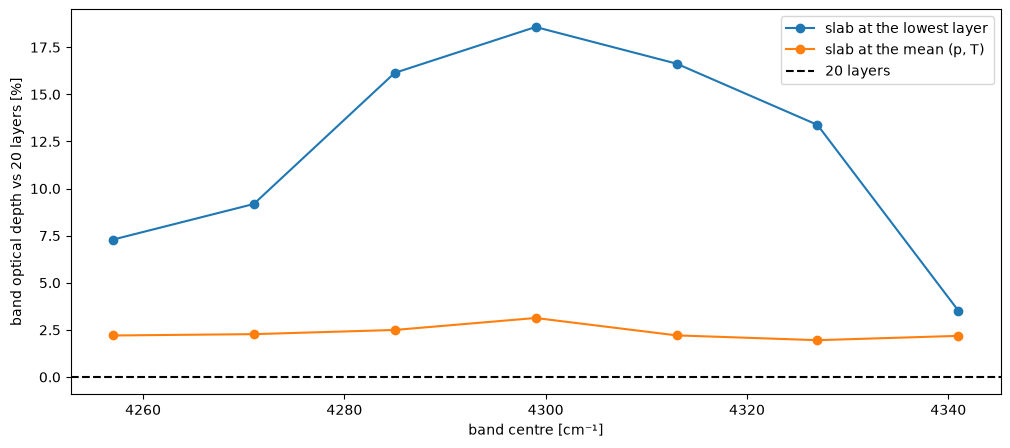

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for tau, label in [
    (tau_surface, "slab at the lowest layer"),
    (tau_mean, "slab at the mean (p, T)"),
]:
    ax.plot(centres, 100 * (tau / tau_layers - 1), "o-", label=label)
ax.axhline(0.0, color="k", linestyle="--", label="20 layers")
ax.set_xlabel("band centre [cm⁻¹]")
ax.set_ylabel("band optical depth vs 20 layers [%]")
ax.legend()
plt.show()

The slab at the lowest layer broadens every line as if all the methane sat near the surface. Its band optical depth is off by up to 19 %. The slab at the mean $(p, T)$ is off by up to 3 %. That is an error of the model's structure, and it is 30 times the 0.1 % to which v0 holds its tables' interpolation. The layers are not decoration: they are the first thing v0 changes.

## 4. The matched-filter target from autodiff

[`unit_absorption_target`](xref:api#radtrax.unit_absorption_target) differentiates $\ln y$ with respect to a column enhancement $\Delta X$ [mol/m²], here spread over the lowest kilometre, by one forward-mode pass. It depends on the scene through the state and the geometry, which is why a target per scene replaces a MODTRAN table. The slab's target is off too, by up to 3.8 % here: a smaller error than in the optical depth, because the plume itself sits in the lowest kilometre, near the surface's pressure.

In [8]:
target = eqx.filter_jit(radtrax.unit_absorption_target)
t_layers = np.asarray(target(model, layered, surface, geometry))
slab = slab_at(p_atm[0], t_k[0])
t_slab = np.asarray(target(model, slab, surface, geometry))
print("t, 20 layers [per mol/m²]:", np.round(t_layers, 4))
err = np.max(np.abs(t_slab / t_layers - 1))
print(f"lowest-layer slab: up to {err:.1%} off")

t, 20 layers [per mol/m²]: [-0.0427 -0.035  -0.0526 -0.0845 -0.0692 -0.0616 -0.0634]
lowest-layer slab: up to 3.8% off


## Summary

- `ForwardModel(opacity, solver, instrument)(state, surface, geometry)` gives one value per band, and every input is differentiable.
- Through one slab at the lowest layer's $(p, T)$, a band's optical depth is off by up to 19 % (18.6 %) from 20 layers; at the column's mean $(p, T)$, by up to 3 % (3.1 %).
- The slab's matched-filter target is off by up to 3.8 %.
- `unit_absorption_target` gives each scene its own matched-filter target, $t = \partial \ln y / \partial \Delta X$.